# Natural fibre composites: Ashby-type selection charts

*Materials & the Environment, companion notebook to Chapter 5.*

Plant fibre reinforced plastics (PFRPs) put flax, hemp or jute in a polymer matrix instead of glass. This notebook rebuilds the selection charts of

> D. U. Shah, *Natural fibre composites: Comprehensive Ashby-type materials selection charts*, Materials & Design 62 (2014) 21–31, [doi:10.1016/j.matdes.2014.05.002](https://doi.org/10.1016/j.matdes.2014.05.002)

from the paper's four supplementary tables:

| Table | Content | Used in |
|---|---|---|
| S1 | 12 fibres: density, modulus, strength, cost, embodied energy | §2 |
| S2 | 35 composites: process, reinforcement form, matrix, fibre content, modulus, strength | §4–6 |
| S3 | 4 reinforcement forms: efficiency factors, cost, embodied energy | §3 |
| S4 | 15 composites: tensile and fatigue strength at 10⁶ cycles | §7 |

**What you will do:** plot fibres and composites on four bases (absolute, per density, per cost, per embodied energy), test the rule of mixtures, rank composites with performance indices, compare them with conventional materials and with glass, and check the fatigue rule of thumb. The last section is an exercise.

**Note on cost and energy.** The paper does not tabulate composite cost or embodied energy. Following its footnote, they are estimated per kg from the weight fractions of fibre and matrix. Reinforcement values by form are mid-range values from Table S3. Matrix costs are within the paper's ranges; matrix embodied energies are typical values, not from the paper (PP 95, UP 85, VE 100, epoxy 130 MJ/kg).

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Polygon, Patch
from matplotlib.lines import Line2D
from scipy.spatial import ConvexHull

URL = "https://raw.githubusercontent.com/MaterialsandtheEnvironment/MaterialsandtheEnvironment.github.io/main/data/nfc.json"
LOCAL = "../data/nfc.json"
D = json.load(open(LOCAL)) if os.path.exists(LOCAL) else json.load(urllib.request.urlopen(URL))
print(D["source"])
print(len(D["fibres"]), "fibres,", len(D["composites"]), "composites,", len(D["fatigue"]), "fatigue results")

# colours shared with the web chapter
GROUP_COL = {"Bast": "#2a78d6", "Leaf": "#e34948", "Seed": "#1baf7a", "Other": "#eda100", "Synthetic": "#47524e"}
FORMS = ["Pellets", "Nonwoven", "Multiaxial", "Unidirectional"]
FORM_COL = {"Pellets": "#e87ba4", "Nonwoven": "#1baf7a", "Multiaxial": "#eb6834", "Unidirectional": "#2a78d6"}
from matplotlib.ticker import FuncFormatter, NullFormatter
def logax(ax):
    # log axes with plain-number labels (1, 10, 100...) and no cluttered minor labels
    ax.set_xscale("log"); ax.set_yscale("log")
    for a in (ax.xaxis, ax.yaxis):
        a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); a.set_minor_formatter(NullFormatter())
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})

Shah DU (2014) Materials & Design 62:21-31, doi:10.1016/j.matdes.2014.05.002, Supplementary Tables 1-4
12 fibres, 35 composites, 15 fatigue results


## 1. The data as tables

Fibre properties are **ranges** `[min, max]`, as reported in the literature. For tables we show the mid-range value.

In [2]:
mid = lambda r: (r[0] + r[1]) / 2
fib = pd.DataFrame([{ "fibre": f["name"], "group": f["group"], "ρ (g/cm³)": mid(f["rho"]), "E (GPa)": mid(f["E"]),
                      "σ (MPa)": mid(f["s"]), "E/ρ": mid(f["Esp"]), "σ/ρ": mid(f["ssp"]),
                      "cost (£/kg)": mid(f["cost"]), "energy (MJ/kg)": mid(f["ee"])} for f in D["fibres"]]).set_index("fibre")
fib.round(2)

,group,ρ (g/cm³),E (GPa),σ (MPa),E/ρ,σ/ρ,cost (£/kg),energy (MJ/kg)
fibre,,,,,,,,
Flax,Bast,1.50,64.0,689.0,42.0,452.5,1.35,12.0
Hemp,Bast,1.50,46.0,605.0,30.5,397.5,1.00,10.5
Jute,Bast,1.40,40.0,583.0,28.5,412.0,0.20,6.0
Sisal,Leaf,1.42,18.5,523.5,12.5,365.5,0.75,10.5
Pineapple,Leaf,1.50,24.0,448.5,15.5,292.0,0.45,2.0
Banana,Leaf,1.33,20.0,646.5,15.0,486.0,0.70,2.0
Cotton,Seed,1.55,9.0,442.0,10.0,282.0,2.70,47.5
Coir,Seed,1.15,9.0,153.0,8.5,132.5,0.20,2.0
Oil palm,Seed,1.12,8.0,248.0,8.0,257.0,0.30,2.0


In [3]:
comp = pd.DataFrame(D["composites"])
comp["type"] = np.where(comp["matrix"] == "PP", "Thermoplastic", "Thermoset")
comp[["name", "form", "process", "matrix", "vf", "wf", "rho", "E", "s", "Esp", "ssp", "cost", "ee", "ref"]].rename(columns={
    "rho": "ρ", "E": "E (GPa)", "s": "σ (MPa)", "Esp": "E/ρ", "ssp": "σ/ρ", "cost": "C (£/kg, est.)", "ee": "H (MJ/kg, est.)"}).round(2)

,name,form,process,matrix,vf,wf,ρ,E (GPa),σ (MPa),E/ρ,σ/ρ,"C (£/kg, est.)","H (MJ/kg, est.)",ref
0,Flax/PP,Pellets,Injection moulding,PP,0.21,0.30,1.06,1.7,27,1.6,26,1.18,69.5,43
1,Hemp/PP,Pellets,Injection moulding,PP,0.20,0.30,1.00,1.5,30,1.5,29,1.18,69.5,44
2,Flax/PP + 5 wt% MAPP,Pellets,Injection moulding,PP,0.21,0.30,1.05,2.1,38,2.0,36,1.18,69.5,43
3,Flax/PP,Nonwoven,Compression moulding,PP,0.40,0.55,1.10,8.8,57,8.0,52,1.39,62.3,45
4,Jute/PP,Nonwoven,Compression moulding,PP,0.30,0.41,1.03,3.7,27,3.6,26,1.35,70.5,5
5,Flax/PP + 3.5 wt% MAPP,Nonwoven,Compression moulding,PP,0.40,0.54,1.10,8.6,68,7.8,62,1.39,62.3,45
6,Flax/UP,Nonwoven,Compression moulding,UP,0.18,0.21,1.26,11.0,80,8.7,63,2.29,74.5,46
7,Hemp/UP,Nonwoven,Compression moulding,UP,0.41,0.47,1.30,5.6,36,4.3,28,2.03,61.5,47
8,"Hemp/UP, 5% NaOH",Nonwoven,Compression moulding,UP,0.40,0.46,1.29,7.5,46,5.8,35,2.04,62.0,47
9,Flax/UP,Nonwoven,Vacuum infusion,UP,0.30,0.37,1.21,6.3,61,5.2,50,2.13,66.4,48


## 2. Plant fibres on Ashby charts

Each fibre is drawn as an ellipse spanning its range of modulus and strength, on log scales, as in Fig. 5 of the paper. The four bases are:

* **absolute**: $E$, $\sigma$;
* **per density** (light design): $E/\rho$, $\sigma/\rho$;
* **per cost** (cheap design): $E/(C\rho)$, $\sigma/(C\rho)$, with $C$ in £/kg;
* **per embodied energy** (low-energy design): $E/(H\rho)$, $\sigma/(H\rho)$, with $H$ in MJ/kg.

Dividing a range by another range gives a wider range: the low end uses the highest cost, the high end the lowest.

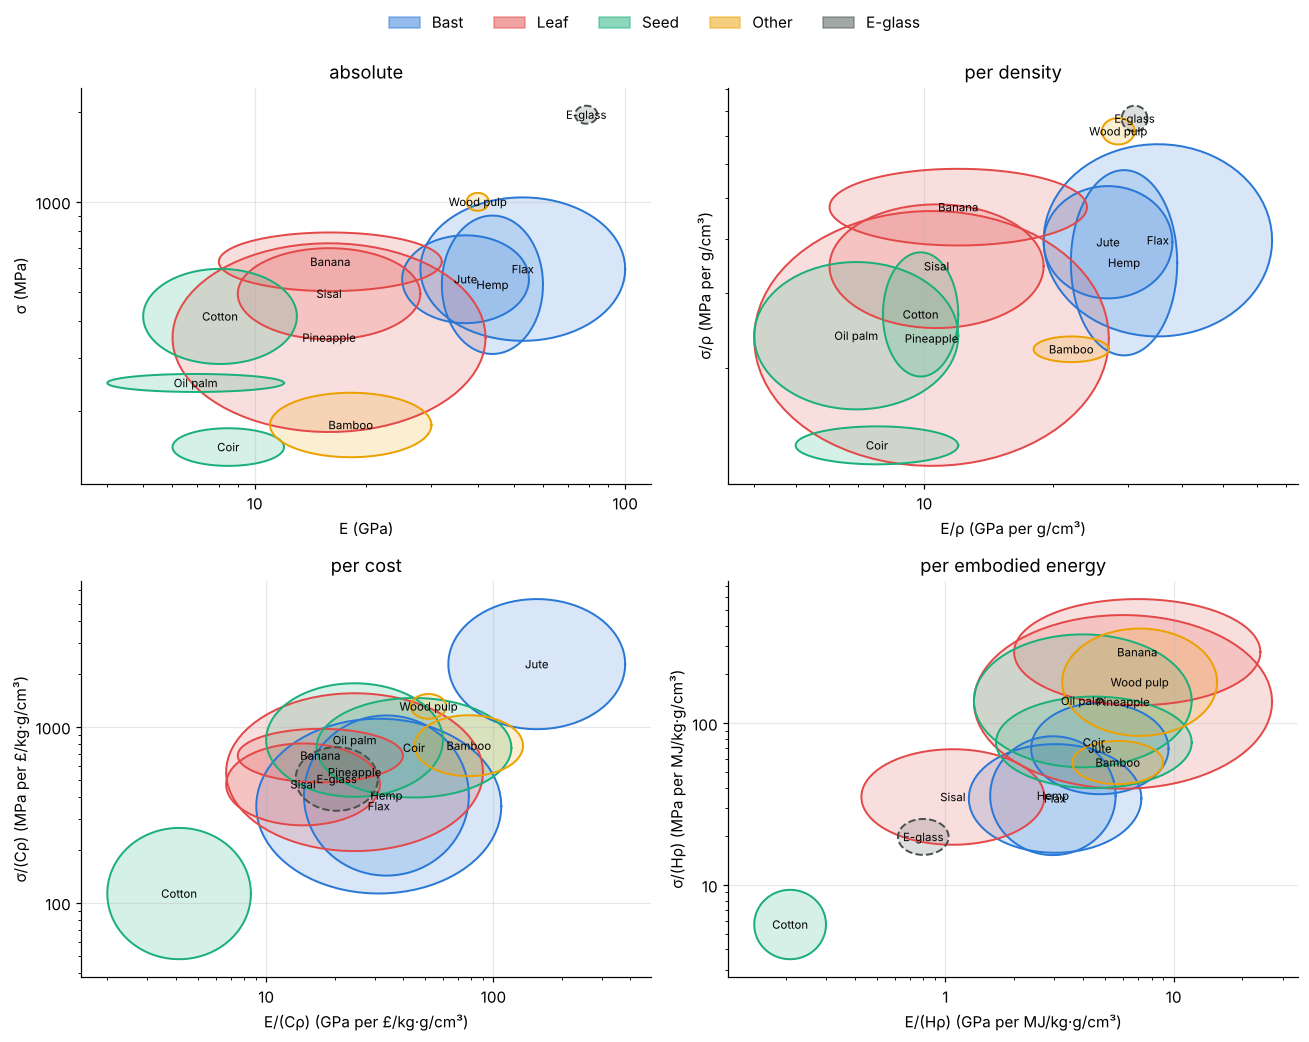

In [4]:
BASES = {"abs": "absolute", "rho": "per density", "cost": "per cost", "ee": "per embodied energy"}
UNITS = {"abs": ("E (GPa)", "σ (MPa)"), "rho": ("E/ρ (GPa per g/cm³)", "σ/ρ (MPa per g/cm³)"),
         "cost": ("E/(Cρ) (GPa per £/kg·g/cm³)", "σ/(Cρ) (MPa per £/kg·g/cm³)"),
         "ee": ("E/(Hρ) (GPa per MJ/kg·g/cm³)", "σ/(Hρ) (MPa per MJ/kg·g/cm³)")}

def fibre_box(f, basis):
    """[[xmin, xmax], [ymin, ymax]] of a fibre on a basis."""
    div = lambda a, d: [a[0] / d[1], a[1] / d[0]]
    if basis == "abs":  return [f["E"], f["s"]]
    if basis == "rho":  return [f["Esp"], f["ssp"]]
    if basis == "cost": return [div(f["Esp"], f["cost"]), div(f["ssp"], f["cost"])]
    return [div(f["Esp"], f["ee"]), div(f["ssp"], f["ee"])]

def log_ellipse(ax, xr, yr, color, label, dashed=False):
    # an ellipse inscribed in the range box, drawn in log space
    lx, ly = np.log10(xr), np.log10(yr)
    cx, cy = lx.mean(), ly.mean()
    rx, ry = max((lx[1] - lx[0]) / 2, 0.03), max((ly[1] - ly[0]) / 2, 0.03)
    t = np.linspace(0, 2 * np.pi, 80)
    xs, ys = 10 ** (cx + rx * np.cos(t)), 10 ** (cy + ry * np.sin(t))
    ax.fill(xs, ys, color=color, alpha=.18, lw=0)
    ax.plot(xs, ys, color=color, lw=1.3, ls="--" if dashed else "-")
    ax.text(10 ** cx, 10 ** cy, label, ha="center", va="center", fontsize=7.5)

fig, axs = plt.subplots(2, 2, figsize=(12, 9.5))
for ax, b in zip(axs.flat, BASES):
    for f in D["fibres"]:
        xr, yr = fibre_box(f, b)
        log_ellipse(ax, xr, yr, GROUP_COL[f["group"]], f["name"], dashed=f["group"] == "Synthetic")
    ax.autoscale(); logax(ax)
    ax.set_xlabel(UNITS[b][0]); ax.set_ylabel(UNITS[b][1]); ax.set_title(BASES[b])
fig.legend([Patch(color=c, alpha=.5) for c in GROUP_COL.values()], ["Bast", "Leaf", "Seed", "Other", "E-glass"], loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .96)); plt.show()

In [5]:
# ranking by the product of the two mid-range values (geometric means), basis by basis
def score(f, b):
    xr, yr = fibre_box(f, b)
    return np.sqrt(xr[0] * xr[1]) * np.sqrt(yr[0] * yr[1])
rank = pd.DataFrame({BASES[b]: [f["name"] for f in sorted(D["fibres"], key=lambda f: -score(f, b))] for b in BASES}, index=range(1, 13))
rank

,absolute,per density,per cost,per embodied energy
1,E-glass,E-glass,Jute,Banana
2,Wood pulp,Wood pulp,Wood pulp,Wood pulp
3,Flax,Flax,Bamboo,Pineapple
4,Hemp,Jute,Coir,Oil palm
5,Jute,Hemp,Oil palm,Coir
6,Banana,Banana,Hemp,Jute
7,Sisal,Bamboo,Pineapple,Bamboo
8,Pineapple,Sisal,Banana,Hemp
9,Cotton,Cotton,Flax,Flax
10,Bamboo,Pineapple,E-glass,Sisal


**Reading the charts.**

* In absolute terms E-glass is far ahead.
* Per unit density, glass (2.55 g/cm³) loses its stiffness lead: flax and hemp match its specific modulus (31 GPa per g/cm³).
* Per unit cost, jute and wood pulp lead and cotton trails.
* Per unit embodied energy, by-product fibres (banana, pineapple, coir, oil palm) lead because they carry none of the burden of growing the plant, and E-glass falls to 11th of 12.

These are **raw fibres**: yarns and fabrics cost and embody much more, which the next section accounts for.

## 3. Reinforcement form and the rule of mixtures

Krenchel's rule of mixtures corrects the fibre contribution with a length efficiency $\eta_l$ and an orientation efficiency $\eta_o$:

$$E_c \approx \eta_l\,\eta_o\,v_f\,E_f + (1-v_f)\,E_m, \qquad \rho_c = v_f\rho_f + (1-v_f)\rho_m .$$

Table S3 gives typical values of $\eta_l\eta_o$ for each form.

In [6]:
forms = pd.DataFrame(D["forms"]).T[["fibre", "length", "eta", "cost", "ee"]]
forms.columns = ["fibre", "length", "η_l·η_o", "cost (£/kg)", "energy (MJ/kg)"]
forms

,fibre,length,η_l·η_o,cost (£/kg),energy (MJ/kg)
Pellets,SF,<1 mm,"[0.0, 0.11]","[0.5, 1.5]","[5, 15]"
Nonwoven,SF,3-30 mm,"[0.19, 0.36]","[1, 2]","[30, 40]"
Multiaxial,LF,>30 mm,"[0.25, 0.5]","[10, 50]","[54, 146]"
Unidirectional,LF,>30 mm,"[1.0, 1.0]","[10, 40]","[54, 146]"


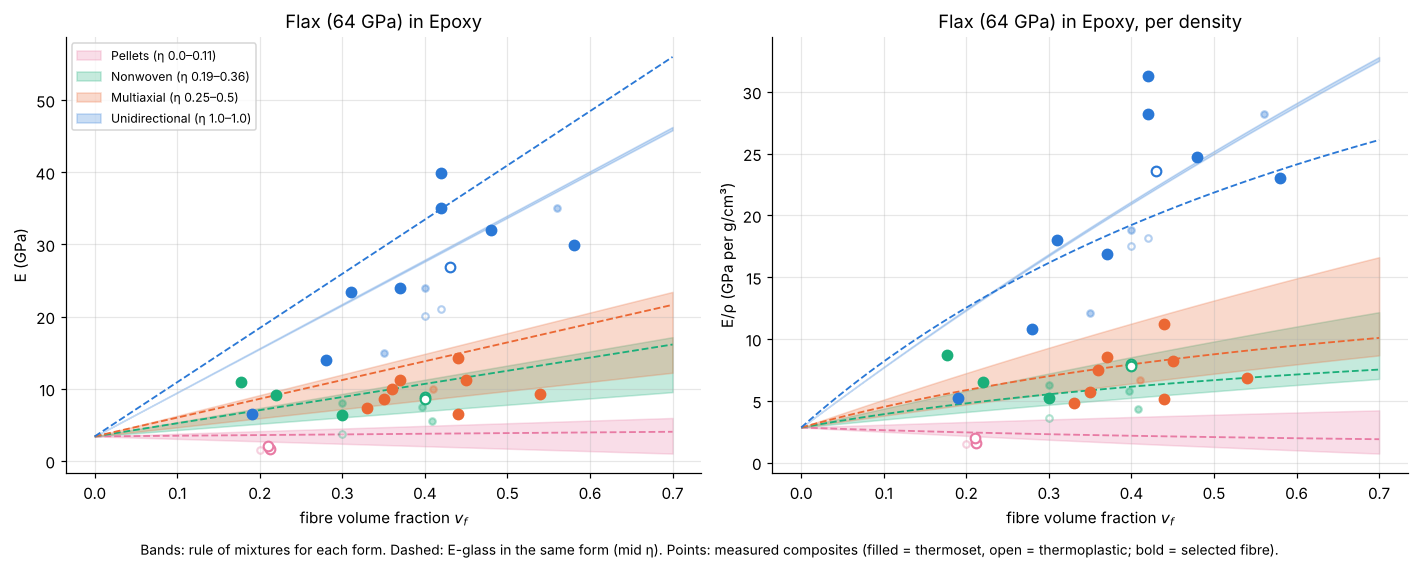

In [7]:
FIB = {f["name"]: f for f in D["fibres"]}
MAT = D["matrices"]

def rule_of_mixtures(vf, Ef, rho_f, eta, matrix="Epoxy"):
    m = MAT[matrix]
    Em = mid(m["E"]) if m["E"] else 3.0
    E = eta * vf * Ef + (1 - vf) * Em
    rho = vf * rho_f + (1 - vf) * m["rho"]
    return E, rho

def plot_rom(fibre="Flax", Ef=None, matrix="Epoxy", specific=False, glass=True, ax=None):
    f = FIB[fibre]; Ef = Ef or mid(f["E"]); rf = mid(f["rho"])
    ax = ax or plt.gca()
    vf = np.linspace(0, .7, 71)
    val = lambda E, r: E / r if specific else E
    for k in FORMS:
        lo, hi = D["forms"][k]["eta"]
        a = val(*rule_of_mixtures(vf, Ef, rf, lo, matrix)); b = val(*rule_of_mixtures(vf, Ef, rf, max(hi, lo + .01), matrix))
        ax.fill_between(vf, a, b, color=FORM_COL[k], alpha=.25, label=f"{k} (η {lo}–{hi})")
        if glass:
            ax.plot(vf, val(*rule_of_mixtures(vf, 78.5, 2.55, mid(D["forms"][k]["eta"]), matrix)), "--", color=FORM_COL[k], lw=1.2)
    for _, c in comp.iterrows():
        on = c["fibre"] == fibre
        ax.scatter(c["vf"], c["Esp"] if specific else c["E"], s=40 if on else 18, alpha=1 if on else .35,
                   facecolor=FORM_COL[c["form"]] if c["type"] == "Thermoset" else "white", edgecolor=FORM_COL[c["form"]], lw=1.4, zorder=3)
    ax.set_xlabel("fibre volume fraction $v_f$"); ax.set_ylabel("E/ρ (GPa per g/cm³)" if specific else "E (GPa)")
    ax.set_title(f"{fibre} ({Ef:.0f} GPa) in {matrix}" + (", per density" if specific else ""))

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
plot_rom("Flax", 64, "Epoxy", False, ax=axs[0]); plot_rom("Flax", 64, "Epoxy", True, ax=axs[1])
axs[0].legend(fontsize=8, loc="upper left")
fig.text(.5, -.02, "Bands: rule of mixtures for each form. Dashed: E-glass in the same form (mid η). Points: measured composites (filled = thermoset, open = thermoplastic; bold = selected fibre).", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
# a direct comparison at 40% fibre in epoxy, unidirectional
for name, Ef, rf in [("Flax (64 GPa)", 64, 1.5), ("E-glass", 78.5, 2.55)]:
    E, r = rule_of_mixtures(.4, Ef, rf, 1.0)
    print(f"{name:14s} UD, vf = 40%:  E = {E:5.1f} GPa,  ρ = {r:.2f} g/cm³,  E/ρ = {E / r:5.1f}")

Flax (64 GPa)  UD, vf = 40%:  E =  27.6 GPa,  ρ = 1.32 g/cm³,  E/ρ =  20.9
E-glass        UD, vf = 40%:  E =  33.4 GPa,  ρ = 1.74 g/cm³,  E/ρ =  19.2


Glass gives the stiffer composite, but per unit density **aligned flax and glass are about equal**: that is the core of the case for plant fibres in stiffness-limited, weight-sensitive parts. Most measured unidirectional composites fall a little below the UD line (porosity, fibre damage, imperfect alignment); pellets barely improve on the matrix.

## 4. Selection charts for plant fibre composites

Each composite is a point; a balloon (convex hull, in log space) encloses each reinforcement form, as in Fig. 6 of the paper. Filled markers are thermosets, open markers thermoplastics; grey crosses are the neat matrices.

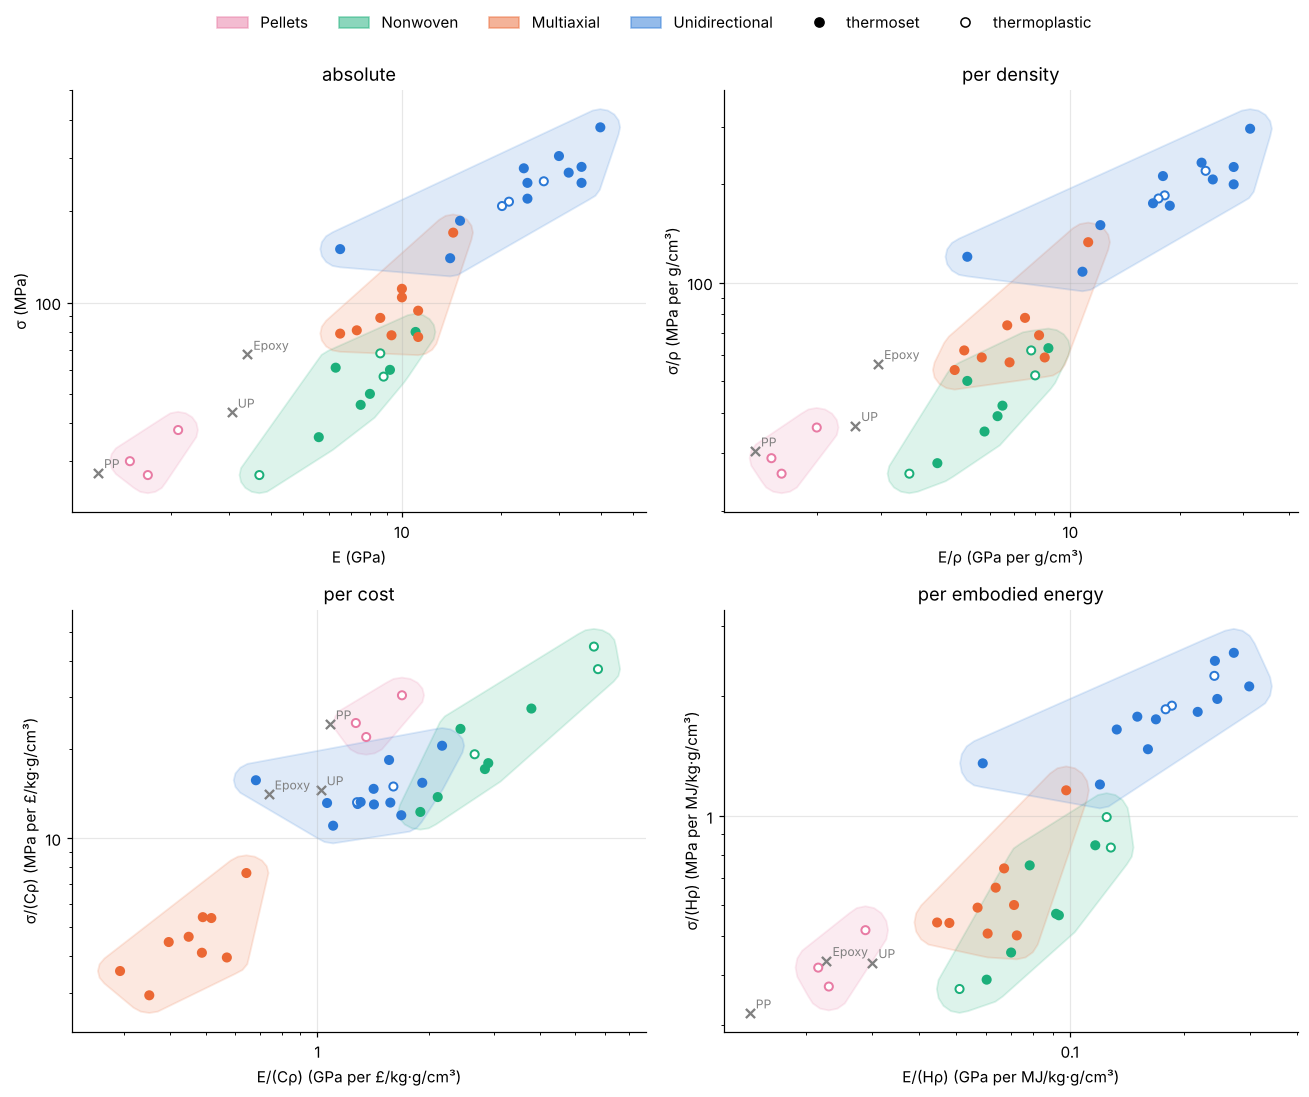

In [9]:
def comp_xy(df, basis):
    if basis == "abs":  return df["E"], df["s"]
    if basis == "rho":  return df["Esp"], df["ssp"]
    if basis == "cost": return df["Esp"] / df["cost"], df["ssp"] / df["cost"]
    return df["Esp"] / df["ee"], df["ssp"] / df["ee"]

def log_hull(ax, x, y, color, pad=0.06):
    # convex hull of points, padded by a small circle in log space so even 3 points give a balloon
    lx, ly = np.log10(np.asarray(x, float)), np.log10(np.asarray(y, float))
    t = np.linspace(0, 2 * np.pi, 16, endpoint=False)
    P = np.array([[a + pad * np.cos(u), b + pad * np.sin(u)] for a, b in zip(lx, ly) for u in t])
    H = P[ConvexHull(P).vertices]
    ax.add_patch(Polygon(10 ** H, closed=True, facecolor=color, alpha=.15, edgecolor=color, lw=1.2))

neat = {k: m for k, m in MAT.items() if m["E"]}
def neat_xy(m, basis):
    E, s, Esp, ssp = mid(m["E"]), mid(m["s"]), mid(m["Esp"]), mid(m["ssp"])
    return {"abs": (E, s), "rho": (Esp, ssp), "cost": (Esp / m["cost"], ssp / m["cost"]), "ee": (Esp / m["ee"], ssp / m["ee"])}[basis]

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for ax, b in zip(axs.flat, BASES):
    x, y = comp_xy(comp, b)
    for k in FORMS:
        sel = comp["form"] == k
        log_hull(ax, x[sel], y[sel], FORM_COL[k])
        ax.scatter(x[sel], y[sel], s=28, lw=1.3, edgecolor=FORM_COL[k],
                   facecolor=[FORM_COL[k] if t == "Thermoset" else "white" for t in comp.loc[sel, "type"]], zorder=3)
    for k, m in neat.items():
        px, py = neat_xy(m, b); ax.scatter(px, py, marker="x", color="grey"); ax.annotate(k, (px, py), xytext=(4, 3), textcoords="offset points", fontsize=8, color="grey")
    logax(ax)
    ax.set_xlabel(UNITS[b][0]); ax.set_ylabel(UNITS[b][1]); ax.set_title(BASES[b])
handles = [Patch(color=FORM_COL[k], alpha=.5, label=k) for k in FORMS] + [
    Line2D([], [], marker="o", ls="", mfc="k", mec="k", label="thermoset"), Line2D([], [], marker="o", ls="", mfc="w", mec="k", label="thermoplastic")]
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .96)); plt.show()

In [10]:
# strength rises with stiffness at roughly 10 MPa per GPa (least squares through the origin)
k = (comp["s"] * comp["E"]).sum() / (comp["E"] ** 2).sum()
print(f"σ ≈ {k:.1f} MPa per GPa of E")
# ranges by form
comp.groupby("form")[["E", "s"]].agg(["min", "max"]).loc[FORMS]

σ ≈ 9.2 MPa per GPa of E


E          s     
                min   max  min  max
form                               
Pellets         1.5   2.1   27   38
Nonwoven        3.7  11.0   27   80
Multiaxial      6.5  14.3   77  170
Unidirectional  6.5  39.9  140  378

**Four observations** (all in the paper):

1. **The form governs.** Pellets < nonwovens < multiaxials < unidirectionals. UD composites are 2–20× stiffer and stronger than nonwovens.
2. **Matrix and process shift properties within a form.** Thermosets beat thermoplastics. Fibre fraction rises and porosity falls from hand lay-up through vacuum infusion, RTM and compression moulding to prepregging.
3. **Per unit cost the order flips.** Aligned yarns and fabrics cost 10–50 £/kg against 0.5–2 £/kg for pellets and mats. Nonwoven PP composites win, pellets match UD, and multiaxials come last.
4. **Per unit energy the specific order returns.** Forms differ less in energy than in cost, and the matrix carries much of it.

## 5. Ranking with performance indices

A chart screens; an index ranks. The table below lists Ashby's indices for a tie (tension) and a panel (bending), divided by density, by cost × density, or by energy × density.

In [11]:
INDICES = {
    "E/ρ  (stiff tie, min mass)":             lambda c: c.Esp,
    "E^1/3/ρ  (stiff panel, min mass)":       lambda c: np.cbrt(c.E) / c.rho,
    "σ/ρ  (strong tie, min mass)":            lambda c: c.ssp,
    "σ^1/2/ρ  (strong panel, min mass)":      lambda c: np.sqrt(c.s) / c.rho,
    "E/(Cρ)  (stiff tie, min cost)":          lambda c: c.Esp / c.cost,
    "E^1/3/(Cρ)  (stiff panel, min cost)":    lambda c: np.cbrt(c.E) / c.rho / c.cost,
    "σ/(Cρ)  (strong tie, min cost)":         lambda c: c.ssp / c.cost,
    "E/(Hρ)  (stiff tie, min energy)":        lambda c: c.Esp / c.ee,
    "E^1/3/(Hρ)  (stiff panel, min energy)":  lambda c: np.cbrt(c.E) / c.rho / c.ee,
    "σ/(Hρ)  (strong tie, min energy)":       lambda c: c.ssp / c.ee,
}
def top(index, n=5):
    v = INDICES[index](comp)
    out = comp.assign(index=v).sort_values("index", ascending=False).head(n)
    return out[["name", "form", "process", "matrix", "vf", "index"]].round(3)

top("E^1/3/(Cρ)  (stiff panel, min cost)")

,name,form,process,matrix,vf,index
3,Flax/PP,Nonwoven,Compression moulding,PP,0.40,1.350
5,Flax/PP + 3.5 wt% MAPP,Nonwoven,Compression moulding,PP,0.40,1.336
4,Jute/PP,Nonwoven,Compression moulding,PP,0.30,1.114
2,Flax/PP + 5 wt% MAPP,Pellets,Injection moulding,PP,0.21,1.034
1,Hemp/PP,Pellets,Injection moulding,PP,0.20,0.970


**Design case 1: a car door trim panel**, a stiff panel at minimum cost. Nonwoven flax/PP and jute/PP lead, then injection-moulded PP composites: exactly the parts the car industry makes.

In [12]:
top("E/ρ  (stiff tie, min mass)")

,name,form,process,matrix,vf,index
24,Flax/epoxy,Unidirectional,Prepregging,Epoxy,0.42,31.3
18,Jute/UP,Unidirectional,Compression moulding,UP,0.56,28.2
22,Flax/epoxy,Unidirectional,RTM,Epoxy,0.42,28.2
25,Flax/epoxy,Unidirectional,Prepregging,Epoxy,0.48,24.7
12,Flax/PP,Unidirectional,Compression moulding,PP,0.43,23.6


**Design case 2: a light, stiff spar cap**, a stiff tie at minimum mass. Unidirectional flax/epoxy prepreg leads at 31 GPa per g/cm³.

In [13]:
# the winning form for every index
pd.DataFrame({"winner": {k: f"{top(k, 1).iloc[0]['name']} ({top(k, 1).iloc[0]['form'].lower()})" for k in INDICES},
              "best form in top 5": {k: top(k)["form"].mode()[0] for k in INDICES}})

,winner,best form in top 5
"E/ρ (stiff tie, min mass)",Flax/epoxy (unidirectional),Unidirectional
"E^1/3/ρ (stiff panel, min mass)",Flax/epoxy (unidirectional),Unidirectional
"σ/ρ (strong tie, min mass)",Flax/epoxy (unidirectional),Unidirectional
"σ^1/2/ρ (strong panel, min mass)",Flax/epoxy (unidirectional),Unidirectional
"E/(Cρ) (stiff tie, min cost)",Flax/PP (nonwoven),Nonwoven
"E^1/3/(Cρ) (stiff panel, min cost)",Flax/PP (nonwoven),Nonwoven
"σ/(Cρ) (strong tie, min cost)",Flax/PP + 3.5 wt% MAPP (nonwoven),Nonwoven
"E/(Hρ) (stiff tie, min energy)",Jute/UP (unidirectional),Unidirectional
"E^1/3/(Hρ) (stiff panel, min energy)",Flax/PP (nonwoven),Unidirectional
"σ/(Hρ) (strong tie, min energy)",Flax/epoxy (unidirectional),Unidirectional


## 6. Against other engineering materials

The 22 materials of Chapter 1 (CES moduli and densities; strengths are approximate handbook values) placed with the four PFRP balloons. Elastomers and flexible foam are left out; they sit far to the left.

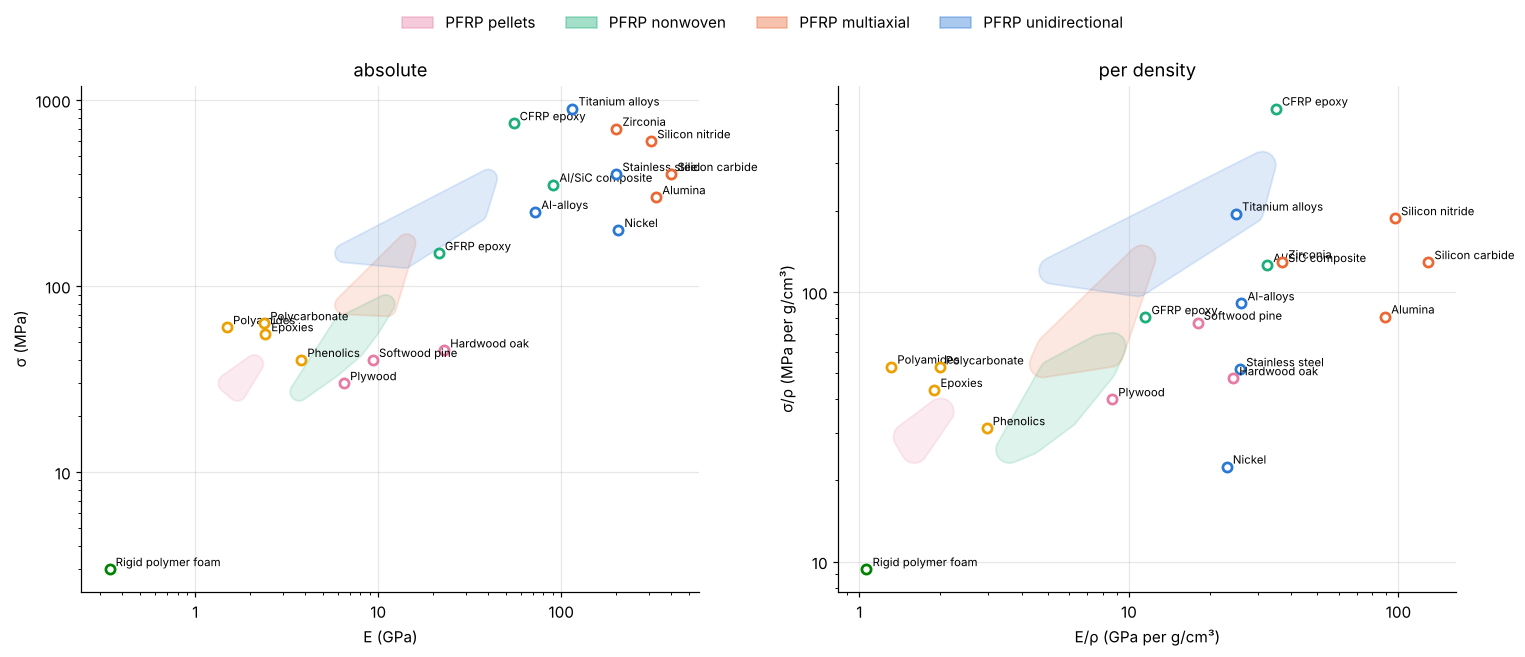

In [14]:
m22 = pd.DataFrame(D["materials22"])
m22["r"] = m22["rho"] / 1000
m22 = m22[m22["E"] / m22["r"] > .5]
FAM_COL = {"Metals & alloys": "#2a78d6", "Technical ceramics": "#eb6834", "Composites": "#1baf7a", "Polymers": "#eda100",
           "Natural materials": "#e87ba4", "Foams": "#008300", "Elastomers": "#6250d6"}
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, specific in zip(axs, [False, True]):
    x, y = comp_xy(comp, "rho" if specific else "abs")
    for k in FORMS:
        sel = comp["form"] == k; log_hull(ax, x[sel], y[sel], FORM_COL[k], pad=.05)
    mx = m22["E"] / m22["r"] if specific else m22["E"]; my = m22["sigma"] / m22["r"] if specific else m22["sigma"]
    for (_, m), a, b in zip(m22.iterrows(), mx, my):
        ax.scatter(a, b, facecolor="white", edgecolor=FAM_COL[m["family"]], lw=1.8, zorder=3)
        ax.annotate(m["name"], (a, b), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
    ax.autoscale(); logax(ax)
    ax.set_xlabel(UNITS["rho" if specific else "abs"][0]); ax.set_ylabel(UNITS["rho" if specific else "abs"][1])
    ax.set_title("per density" if specific else "absolute")
fig.legend(handles=[Patch(color=FORM_COL[k], alpha=.4, label="PFRP " + k.lower()) for k in FORMS], loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .94)); plt.show()

In absolute terms PFRPs sit with woods, engineering polymers and glass composites. Per unit density, **unidirectional PFRPs along the fibres match or exceed aluminium alloys and steels**, which are three to six times denser. The paper's comparison with glass composites of the same form concludes that PFRPs compete on **stiffness**, not on **strength**.

## 7. Fatigue

For parts loaded millions of times, the stress that survives 10⁶ cycles serves as an endurance limit. Table S4 shows it scaling with the static tensile strength.

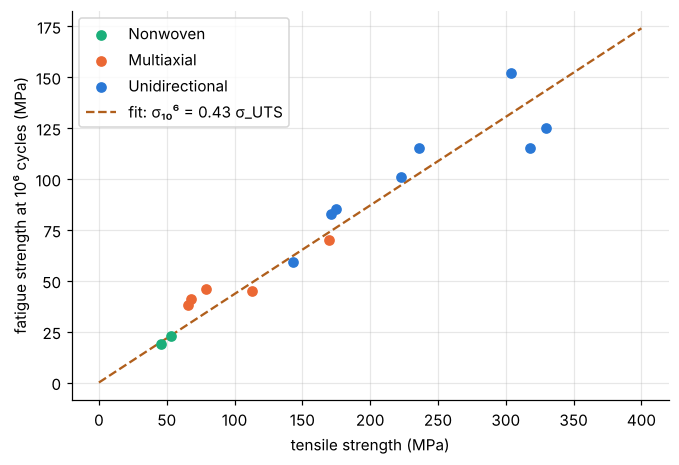

ratio range 36%–60%; ±45° laminates: 58%, 58%, 60%


In [15]:
fat = pd.DataFrame(D["fatigue"])
kf = (fat["fat"] * fat["uts"]).sum() / (fat["uts"] ** 2).sum()
fat["ratio"] = fat["fat"] / fat["uts"]
fig, ax = plt.subplots(figsize=(7, 4.6))
for k in ["Nonwoven", "Multiaxial", "Unidirectional"]:
    s = fat[fat["form"] == k]; ax.scatter(s["uts"], s["fat"], color=FORM_COL[k], label=k, zorder=3)
xs = np.array([0, 400]); ax.plot(xs, kf * xs, "--", color="#b05f1c", label=f"fit: σ₁₀⁶ = {kf:.2f} σ_UTS")
ax.set_xlabel("tensile strength (MPa)"); ax.set_ylabel("fatigue strength at 10⁶ cycles (MPa)"); ax.legend()
plt.show()
print(f"ratio range {fat.ratio.min():.0%}–{fat.ratio.max():.0%}; ±45° laminates:", ", ".join(f"{r:.0%}" for r in fat[fat['name'].str.contains('±45')].ratio))

A first fatigue screen can therefore use static strength × about 0.43; off-axis (±45°) laminates keep a larger fraction (≈ 50–60%) of a low static strength.

## 8. Exercises

1. **Design your own composite.** Use `rule_of_mixtures` to find the hemp volume fraction a nonwoven hemp/PP needs to reach 6 GPa. Is it achievable (nonwovens rarely exceed 40–50% by volume)?
2. **Cost of alignment.** Change the unidirectional reinforcement cost in `D["forms"]` from 10–40 to 5–15 £/kg (a cheaper yarn), recompute `comp["cost"]` and rerun the stiff-panel-at-minimum-cost ranking. At which price do UD composites enter the top five?
3. **Matrix energy.** The matrix embodied energies are assumptions. Set epoxy to 100 MJ/kg and see whether the energy-based rankings change.
4. **A wind turbine blade.** Shah et al. (2013) made a small blade with flax skins 10% lighter than its glass twin. Which index from §5 supports that choice?

In [16]:
# Exercise 1, worked: solve E_c(vf) = target for a nonwoven hemp/PP (mid η of the nonwoven form)
target = 6.0
f, m = FIB["Hemp"], MAT["PP"]
eta = mid(D["forms"]["Nonwoven"]["eta"])
Ef, Em = mid(f["E"]), mid(m["E"])
vf = (target - Em) / (eta * Ef - Em)
print(f"η = {eta:.3f}, E_f = {Ef} GPa, E_m = {Em} GPa  ->  v_f = {vf:.0%} for {target} GPa")

η = 0.275, E_f = 46.0 GPa, E_m = 1.2 GPa  ->  v_f = 42% for 6.0 GPa


In [17]:
# Exercise 2, a starting point: recompute composite cost with a different UD reinforcement price
def recost(ud_cost_range):
    c = comp.copy()
    form_cost = {k: mid(v["cost"]) for k, v in D["forms"].items()}
    form_cost["Unidirectional"] = mid(ud_cost_range)
    c["cost"] = c["wf"] * c["form"].map(form_cost) + (1 - c["wf"]) * c["matrix"].map({k: v["cost"] for k, v in MAT.items()})
    return c

for price in [(10, 40), (5, 15), (2, 6), (1, 3)]:
    c = recost(price)
    v = np.cbrt(c.E) / c.rho / c.cost
    n_ud = (c.assign(v=v).sort_values("v", ascending=False).head(5)["form"] == "Unidirectional").sum()
    print(f"UD reinforcement {price[0]}–{price[1]} £/kg: {n_ud} unidirectional composites in the top 5")

UD reinforcement 10–40 £/kg: 0 unidirectional composites in the top 5
UD reinforcement 5–15 £/kg: 0 unidirectional composites in the top 5
UD reinforcement 2–6 £/kg: 0 unidirectional composites in the top 5
UD reinforcement 1–3 £/kg: 3 unidirectional composites in the top 5


## 9. Takeaways

* **Reinforcement form, not fibre species, decides** the properties of a plant fibre composite.
* **Per unit weight**, aligned flax matches glass in stiffness, not in strength.
* **Per unit cost**, cheap nonwoven mats win; **per unit energy**, the matrix carries much of the burden and aligned composites lead.
* Charts screen only. Moisture, creep, impact, fire and natural variability must be checked before a final choice. The eco audit of Chapter 6 shows why lighter parts often win over their whole life.

**References.** Shah D.U. (2014) *Materials & Design* 62:21–31. Shah D.U., Schubel P.J., Clifford M.J. (2013) *Composites Part B* 52:172–181. Ashby M.F. (2012) *Materials and the Environment*, 2nd ed.